In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import NMF

DATA_PATH = (
    r"D:\Sachin Chakrawarti\Learn\done\thesis"
    r"\ctc_ectd\dataset\synthetic_cti_reports.csv"
)

df = pd.read_csv(DATA_PATH)

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

# Detect relevant columns
columns = {str(c).lower().strip(): c for c in df.columns}

text_col = next(
    (columns[c] for c in ["text", "narrative", "report_text",
                           "description", "content"]
     if c in columns),
    None
)

title_col = next(
    (columns[c] for c in ["title", "report_title"]
     if c in columns),
    None
)

date_col = next(
    (columns[c] for c in ["date", "publication_date",
                           "published_date", "timestamp",
                           "report_date", "created_at"]
     if c in columns),
    None
)

if text_col is None or date_col is None:
    raise ValueError(
        "A text column and a date column are required. "
        f"Available columns: {df.columns.tolist()}"
    )

df["report_text"] = df[text_col].fillna("").astype(str)

if title_col:
    df["report_text"] = (
        df[title_col].fillna("").astype(str)
        + " "
        + df["report_text"]
    )

df["parsed_date"] = pd.to_datetime(
    df[date_col], errors="coerce", utc=True
)

df = df[
    df["report_text"].str.strip().ne("")
    & df["parsed_date"].notna()
].copy()

df["month"] = (
    df["parsed_date"]
    .dt.tz_convert(None)
    .dt.to_period("M")
    .astype(str)
)

df = df.reset_index(drop=True)

print("Usable dated reports:", len(df))
print("Months covered:", df["month"].nunique())

display(df[["parsed_date", "report_text"]].head())

Shape: (10000, 17)
Columns: ['id', 'title', 'text', 'category', 'date', 'source', 'url', 'severity', 'threat_actor', 'malware', 'attack_vector', 'target_sector', 'country', 'cve_id', 'mitre_technique', 'mitre_technique_name', 'indicators']
Usable dated reports: 10000
Months covered: 69


,parsed_date,report_text
0,2021-01-01 00:00:00+00:00,DDoS activity targeting Retail organizations A...
1,2021-01-01 00:00:00+00:00,Web Attack activity targeting Financial Servic...
2,2021-01-01 00:00:00+00:00,Credential Theft activity targeting Retail org...
3,2021-01-01 00:00:00+00:00,Credential Theft activity targeting Government...
4,2021-01-01 00:00:00+00:00,Phishing activity targeting Banking organizati...


In [2]:
if len(df) < 5:
    raise ValueError(
        "At least five usable reports are needed for this prototype."
    )

vectorizer = TfidfVectorizer(
    max_features=5000,
    stop_words="english",
    ngram_range=(1, 2)
)

X_topics = vectorizer.fit_transform(df["report_text"])

if X_topics.shape[1] < 2:
    raise ValueError(
        "Not enough distinct terms to discover multiple topics."
    )

n_topics = min(5, X_topics.shape[0], X_topics.shape[1])

nmf = NMF(
    n_components=n_topics,
    random_state=42,
    init="nndsvda",
    max_iter=500
)

topic_weights = nmf.fit_transform(X_topics)

terms = vectorizer.get_feature_names_out()

for topic_idx, component in enumerate(nmf.components_):
    top_indices = component.argsort()[-10:][::-1]
    top_terms = [terms[i] for i in top_indices]

    print(f"Topic {topic_idx + 1}: {', '.join(top_terms)}")

df["dominant_topic"] = topic_weights.argmax(axis=1) + 1

display(df[["month", "dominant_topic", "report_text"]].head())

Topic 1: activity, followed malicious, gain, followed, incident affecting, activity mapped, actor, activity involving, affecting, incident
Topic 2: activity, campaign, access linked, initial access, sector initial, additional activity, linked, affected systems, affected, campaign involved
Topic 3: behavior involving, activity corresponds, corresponds mitre, corresponds, threat intelligence, detected, monitoring, intelligence, intelligence monitoring, investigation activity
Topic 4: activity, located, investigation reported, targeted organizations, technique, reported mitre, reported, security analysts, activity identified, campaign targeted
Topic 5: web, attack, web attack, attack activity, identified web, attack behavior, detected web, involved web, attack incident, attack campaign


,month,dominant_topic,report_text
0,2021-01,2,DDoS activity targeting Retail organizations A...
1,2021-01,5,Web Attack activity targeting Financial Servic...
2,2021-01,4,Credential Theft activity targeting Retail org...
3,2021-01,2,Credential Theft activity targeting Government...
4,2021-01,4,Phishing activity targeting Banking organizati...


Monthly topic counts:


dominant_topic,1,2,3,4,5
month,,,,,
2021-01,33,30,32,31,13
2021-02,31,36,26,26,16
2021-03,28,37,34,42,14
2021-04,25,24,33,39,14
2021-05,29,28,34,32,10
...,...,...,...,...,...
2026-05,36,42,40,36,11
2026-06,31,34,31,41,14
2026-07,35,34,19,30,25


Monthly topic shares:


dominant_topic,1,2,3,4,5
month,,,,,
2021-01,0.237,0.216,0.230,0.223,0.094
2021-02,0.230,0.267,0.193,0.193,0.119
2021-03,0.181,0.239,0.219,0.271,0.090
2021-04,0.185,0.178,0.244,0.289,0.104
2021-05,0.218,0.211,0.256,0.241,0.075
...,...,...,...,...,...
2026-05,0.218,0.255,0.242,0.218,0.067
2026-06,0.205,0.225,0.205,0.272,0.093
2026-07,0.245,0.238,0.133,0.210,0.175


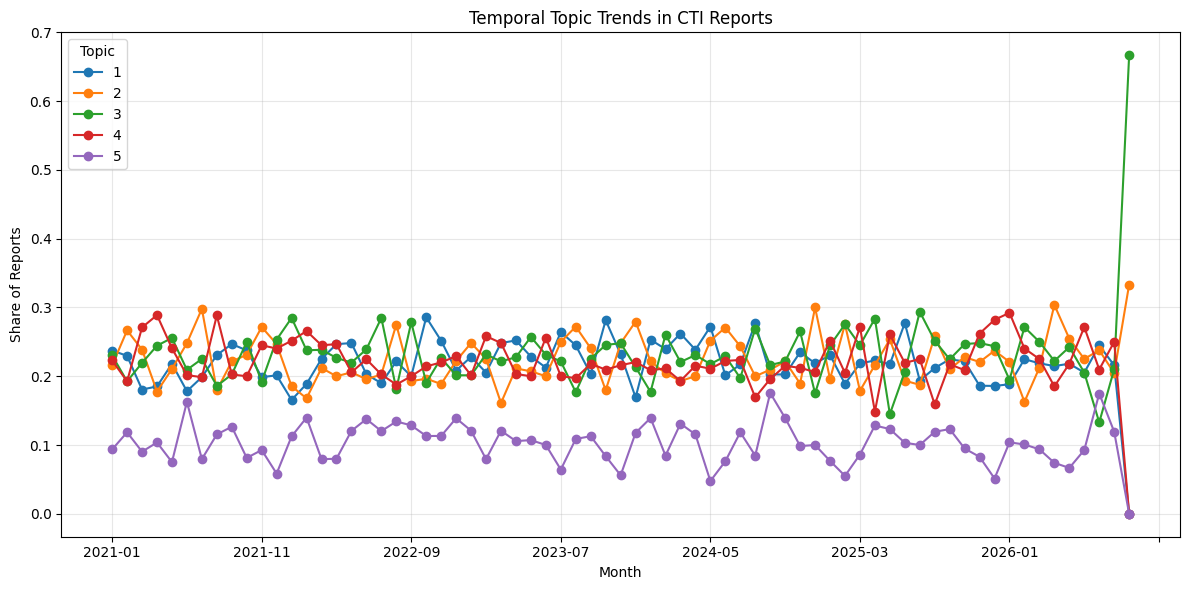

In [3]:
monthly_counts = pd.crosstab(
    df["month"],
    df["dominant_topic"]
).sort_index()

monthly_shares = monthly_counts.div(
    monthly_counts.sum(axis=1),
    axis=0
).fillna(0)

print("Monthly topic counts:")
display(monthly_counts)

print("Monthly topic shares:")
display(monthly_shares.round(3))

monthly_shares.plot(
    figsize=(12, 6),
    marker="o"
)

plt.title("Temporal Topic Trends in CTI Reports")
plt.xlabel("Month")
plt.ylabel("Share of Reports")
plt.legend(title="Topic")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [4]:
alerts = []

months = list(monthly_shares.index)

for i in range(1, len(months)):
    previous_month = months[i - 1]
    current_month = months[i]

    for topic in monthly_shares.columns:
        previous_share = monthly_shares.loc[
            previous_month, topic
        ]

        current_share = monthly_shares.loc[
            current_month, topic
        ]

        report_count = monthly_counts.loc[
            current_month, topic
        ]

        increase = current_share - previous_share

        if increase >= 0.10 and report_count >= 2:
            alerts.append({
                "previous_month": previous_month,
                "current_month": current_month,
                "topic": topic,
                "previous_share": round(previous_share, 3),
                "current_share": round(current_share, 3),
                "increase": round(increase, 3),
                "report_count": int(report_count)
            })

alerts_df = pd.DataFrame(alerts)

if alerts_df.empty:
    print("No topics crossed the exploratory alert threshold.")
else:
    display(alerts_df)

,previous_month,current_month,topic,previous_share,current_share,increase,report_count
0,2024-11,2024-12,2,0.189,0.300,0.111,48
1,2025-04,2025-05,4,0.149,0.261,0.112,36
2,2026-08,2026-09,3,0.210,0.667,0.456,2
